# Temperature-dependent viscoelasticity

This demo shows how to define a temperature-dependent material model. We consider here the
case of linear viscoelasticity with a generalized Maxwell model with temperature-dependent
properties.

Polymer relaxation is often modeled using time-temperature superposition (TTS), for which the
relaxation times shift with temperature, here by an Arrhenius factor. Relaxation curves measured
at different temperatures are then horizontal translations of a single master curve. For a
$N$-branch Prony series, the relaxation modulus reads

$$E(t;T) = E_\infty + \sum_i E_i\,\exp\!\Big(\!-\frac{t}{\tau_i\,a_T(T)}\Big),
  \qquad a_T(T) = \exp\!\Big[\frac{Q}{R}\Big(\frac1T-\frac1{T_\text{ref}}\Big)\Big].$$

with $a_T(T)<1$ above $T_\text{ref}$, i.e. shorter relaxation times and faster relaxation when
hot. This closed form describes a relaxation test at a *fixed* temperature; it is not, by itself,
a constitutive law that can be driven along an arbitrary strain path, still less one in which the
temperature changes while the material is loaded.

We therefore build a genuine viscoelastic constitutive law by composition: an ordinary
`GeneralizedMaxwell` behavior whose relaxation times are a temperature-dependent parameter,
wrapped in a `TemperatureDependent` model. At each step the wrapper feeds the current temperature
to the behavior, resolves the relaxation times to $\tau_i(T)$, and delegates the update to
`GeneralizedMaxwell`. The isothermal Prony response is recovered as a special case, while general
strain and temperature histories are handled by the same code.


```{note}
Note that in the case of linear viscoelasticity, this strategy is equivalent to working with a
reduced-time increment

$$\mathrm d\xi = \frac{\mathrm dt}{a_T(T)}.$$

Indeed, the generalized Maxwell update advances each branch stress over a step
with the closed-form recurrence built from $a_i = \exp(-\Delta t/\tau_i)$. Substituting the
shifted time $\tau_i(T)=\tau_i^\text{ref}a_T(T)$ gives
$a_i=\exp(-\Delta t/(\tau_i^\text{ref}a_T)) = \exp(-\Delta\xi/\tau_i^\text{ref})$ with
$\Delta\xi=\Delta t/a_T(T)$. Hence, the branch relaxes in reduced time $\xi$, and because the
temperature is resolved afresh each step, a temperature that varies under load accumulates
$\xi(t)=\int_0^t \mathrm dt'/a_T(T(t'))$.
```

In [1]:
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib as mpl
import matplotlib.pyplot as plt
import optax
import paramax

import jaxmat.materials as jm
from jaxmat.materials.thermomechanics import TemperatureDependent
from jaxmat.materials.viscoelasticity import GeneralizedMaxwell
from jaxmat.parameters import AbstractParameter, Positive
from jaxmat.tensors import SymmetricTensor2

jax.config.update("jax_enable_x64", True)

T_REF, R_GAS = 300.0, 8.314462618

## A temperature-dependent relaxation-time parameter

The temperature dependence lives in a single parameter: the reference relaxation times
scaled by the Arrhenius shift. We subclass `AbstractParameter` and implement the `evaluate`
method. # Any behavior field holding such a parameter is resolved automatically by
`evaluate_parameters` when the behavior is wrapped as a # `TemperatureDependent` material, so
the behavior itself never needs to know about temperature. # Finally, we use the `Positive()`
constrained field to keep the times and activation energy positive during calibration.

In [2]:
class ShiftedRelaxationTimes(AbstractParameter):
    tau_ref: jax.Array = Positive()  # reference relaxation times (vector)
    Q: jax.Array = Positive()  # activation energy for the TTS shift
    T_ref: float = eqx.field(static=True, default=T_REF)

    def shift(self, T):
        return jnp.exp(self.Q / R_GAS * (1 / T - 1 / self.T_ref))

    def evaluate(self, T):
        return self.tau_ref * self.shift(T)

## Building the model by composition

We build the model from an equilibrium elastic branch, a set of Maxwell branches, and the
temperature-dependent # relaxation times, assembled into a `GeneralizedMaxwell` and wrapped once
as a `TemperatureDependent` model.

In [3]:
nu = 0.3
E_inf = 200.0
Nbranch = 2
E_branches = jnp.array([500.0, 300.0])
tau_ref = jnp.array([30.0, 300.0])
Q = 6.0e4

equilibrium = jm.LinearElasticIsotropic(E=E_inf, nu=nu)
branches = jax.vmap(lambda E: jm.LinearElasticIsotropic(E=E, nu=nu))(E_branches)
maxwell = jm.GeneralizedMaxwell(
    elasticity=equilibrium,
    Nbranch=2,
    viscous_branches=branches,
    relaxation_times=ShiftedRelaxationTimes(tau_ref=tau_ref, Q=Q),
)
truth = jm.TemperatureDependent(maxwell)

The driver scans the wrapped behavior over a strain/temperature history. A uniaxial
deviatoric strain step probes the relaxation Young modulus
$E(t;T)=(1+\nu)\sigma_{11}(t)/\varepsilon_{11}$.

In [4]:
N = 150
ts = jnp.logspace(-1, 3.2, N)
dt_seq = jnp.diff(ts, prepend=0)
EPS0 = 1.0e-3


def strain_step(x):
    return SymmetricTensor2(array=jnp.array([x, -0.5 * x, -0.5 * x, 0.0, 0.0, 0.0]))


def modulus(model, T_seq, dt_seq):
    m = paramax.unwrap(model)

    def step(state, carry):
        x, T, dt = carry
        sig, state = m.constitutive_update((strain_step(x), T), state, dt)
        return state, sig[0, 0]

    _, sig11 = jax.lax.scan(step, m.init_state(), (jnp.full(N, EPS0), T_seq, dt_seq))
    return sig11 * (1 + nu) / EPS0  # computes relaxation Young modulus from deviatoric strain path

## Isothermal response and master-curve collapse

At constant temperature the relaxation curve is a horizontal shift of the reference-temperature
curve by $a_T(T)$. Plotting against reduced time $t/a_T(T)$ collapses them onto one master curve.

In [5]:
def shift_factor(T, Q=6.0e4):
    return jnp.exp(Q / R_GAS * (1 / T - 1 / T_REF))


T_iso = [285.0, 300.0, 315.0]
iso_curves = {T: modulus(truth, jnp.full(N, T), dt_seq) for T in T_iso}

collapse_err = max(
    float(
        jnp.max(jnp.abs(jnp.interp(ts, ts / shift_factor(T), iso_curves[T]) - iso_curves[T_REF]))
        / jnp.max(iso_curves[T_REF])
    )
    for T in T_iso
    if T != T_REF
)
print(
    f"master-curve collapse: curves at all temperatures overlay to within {collapse_err:.1e}",
    " (relative)",
)

master-curve collapse: curves at all temperatures overlay to within 6.6e-02 (relative)


## A non-isothermal history

Holding the strain and ramping the temperature, the wrapped behavior accumulates reduced time
step by step. A common shortcut is to evaluate the isothermal master curve at the *instantaneous*
temperature, $E\big(t/a_T(T(t))\big)$; this rescales the whole elapsed time by the current shift
factor and so ignores the thermal history, it behaves as if the material had spent its entire
past at the present temperature.

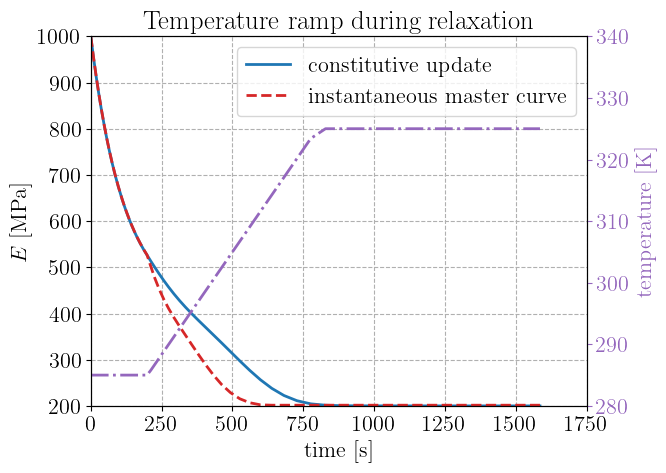

In [6]:
T_ramp = jnp.clip(285.0 + (325.0 - 285.0) * (ts - 200.0) / 600.0, 285.0, 325.0)
E_ramp = modulus(truth, T_ramp, dt_seq)

E_ref_curve = iso_curves[T_REF]
aT_t = shift_factor(T_ramp)
E_instant = jnp.interp(ts / aT_t, ts, E_ref_curve)  # master curve at instantaneous T

plt.figure()
axa = plt.gca()
axb = axa.twinx()
axb.grid(False)
axb.plot(ts, T_ramp, "-.", color="C4")
axb.set_ylabel("temperature [K]", color="C4")
axb.tick_params(axis="y", colors="C4")
axb.set_ylim(280, 340)
axa.plot(ts, E_ramp, "C0-", label="constitutive update")
axa.plot(ts, E_instant, "C3--", label="instantaneous master curve")
axa.set_xlabel("time [s]")
axa.set_ylabel("$E$ [MPa]")
axa.set_title("Temperature ramp during relaxation")
axa.legend()
plt.show()

Under the temperature ramp, the constitutive update and the instantaneous master curve coincide
early and late but diverge through the transition, where the master curve relaxes too quickly.


## Calibration through the wrapper

The activation energy and reference relaxation times are calibrated from noisy
multi-temperature relaxation data. Because they are `Positive()` fields inside the parameter,
the optimiser works on unconstrained log-latents; `paramax.unwrap` reconstructs the physical
values, and gradients flow through the wrapper and the Maxwell update down to the parameter.

In [7]:
data = jnp.stack([iso_curves[T] for T in T_iso]) + 5.0 * jax.random.normal(
    jax.random.PRNGKey(0), (len(T_iso), N)
)
initial_guess_relaxation_times = ShiftedRelaxationTimes(tau_ref=jnp.array([10.0, 1000.0]), Q=3.0e2)
model = TemperatureDependent(
    GeneralizedMaxwell(
        elasticity=equilibrium,
        Nbranch=2,
        viscous_branches=branches,
        relaxation_times=initial_guess_relaxation_times,
    ),
)


def loss(model):
    pred = jnp.stack([modulus(model, jnp.full(N, T), dt_seq) for T in T_iso])
    return jnp.mean((pred - data) ** 2)


opt = optax.adam(5e-2)
opt_state = opt.init(eqx.filter(model, eqx.is_inexact_array))


@eqx.filter_jit
def step(model, opt_state):
    loss_value, g = eqx.filter_value_and_grad(loss)(model)
    updates, opt_state = opt.update(g, opt_state, model)
    return eqx.apply_updates(model, updates), opt_state, loss_value


for i in range(500):
    model, opt_state, loss_value = step(model, opt_state)
    if i % 100 == 0 or i == 499:
        print(f"step {i:4d}   loss = {float(loss_value):8.2f}")

fitted = paramax.unwrap(model).behavior.relaxation_times
true_p = paramax.unwrap(truth).behavior.relaxation_times
print(
    f"\n  tau_ref : {[round(float(x), 1) for x in fitted.tau_ref]}  vs {
        [round(float(x), 1) for x in true_p.tau_ref]
    }"
)
print(f"  Q       : {float(fitted.Q):.3e}  vs {float(true_p.Q):.3e}")

step    0   loss = 16515.59
step  100   loss =   120.17
step  200   loss =    26.22
step  300   loss =    25.71
step  400   loss =    25.68
step  499   loss =    25.68

  tau_ref : [30.0, 295.3]  vs [30.0, 300.0]
  Q       : 5.994e+04  vs 6.000e+04


The relaxation times and the activation energy are recovered from a poor initial guess that spans
the wrong order of magnitude, the log-parameterization letting a single learning rate handle
quantities as disparate as $\tau\sim10$-$100$ s and $Q\sim10^4$. The fit uses only isothermal
data, yet the calibrated model predicts the unseen non-isothermal ramp.

In [8]:
print(
    f"non-isothermal prediction vs ground truth: "
    f"max rel. err = {
        float(jnp.max(jnp.abs(modulus(model, T_ramp, dt_seq) - E_ramp)) / jnp.max(E_ramp)):.1e}"
)

non-isothermal prediction vs ground truth: max rel. err = 1.1e-03


## Results

Sweeping the temperature and evaluating the model in batch shows the relaxation modulus over a
range of temperatures. The initial and final plateaus are common to every curve; increasing the
temperature slides the transition towards shorter times, by roughly a decade per fifteen degrees
for this activation energy. The noisy calibration data (markers) fall on the corresponding curves.

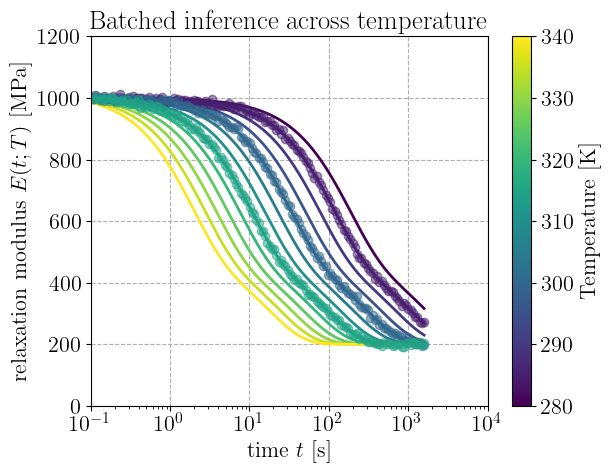

In [9]:
T_sweep = jnp.linspace(280.0, 340.0, 13)
norm = mpl.colors.Normalize(vmin=T_sweep.min(), vmax=T_sweep.max())
cmap = mpl.colormaps["viridis"]
plt.figure()
for T in T_sweep:
    ET = modulus(truth, jnp.full(N, T), dt_seq)
    plt.semilogx(ts[1:], ET[1:], color=cmap(norm(T)), lw=2)
for T, d in zip(T_iso, data):
    plt.semilogx(ts[1:], d[1:], "o", color=cmap(norm(T)), alpha=0.5)
plt.xlabel("time $t$ [s]")
plt.ylabel("relaxation modulus $E(t;T)$ [MPa]")
plt.title("Batched inference across temperature")
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=plt.gca(), label="Temperature [K]")
plt.show()

Rescaling the time axis of each isothermal curve by its shift factor $a_T(T)$ brings them onto a
common master curve. This collapse is the defining signature of a thermorheologically simple
material: a single scalar shift per temperature captures the entire relaxation spectrum, which is
exactly the property the `ShiftedRelaxationTimes` parameter encodes.

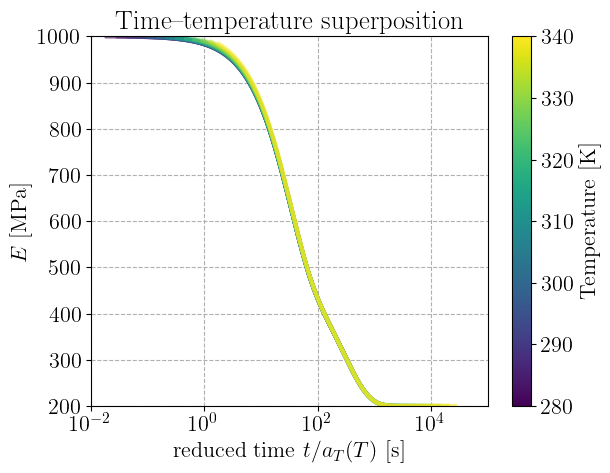

In [10]:
plt.figure()
for T in T_sweep:
    ET = modulus(truth, jnp.full(N, T), dt_seq)
    plt.semilogx(
        ts[1:] / float(shift_factor(T)),
        ET[1:],
        color=cmap(norm(T)),
        lw=3,
        alpha=0.6,
        label=f"{T:.0f} K",
    )
plt.xlabel(r"reduced time $t/a_T(T)$ [s]")
plt.ylabel("$E$ [MPa]")
plt.title("Time-temperature superposition")
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=plt.gca(), label="Temperature [K]")
plt.show()

## Discussion

We have presented a temperature-dependent Generalized Maxwell behavior implementation that can be
driven along any strain and temperature history. Temperature enters only
through the shift of the relaxation times, equivalently through the reduced-time increment
$\mathrm d\xi=\mathrm dt/a_T(T)$, so the viscous stresses relax at different rates. At
constant temperature this reproduces the isothermal Prony response and the master-curve collapse;
under a varying temperature it departs from the instantaneous master curve by 30% here,
the reduced time $\int\mathrm dt/a_T(T)$ carrying a thermal history that the master
curve discards. Identified on isothermal tests alone, the model then predicts non-isothermal
loadings to within the time-integration error.

The construction is entirely by composition. The temperature dependence is isolated in a single
`AbstractParameter`, `ShiftedRelaxationTimes`, the mechanical model is an unmodified
`GeneralizedMaxwell`; and `TemperatureDependent` ties them together, resolving the parameter at
each # step and delegating to the existing update. The whole chain is differentiable, so the
temperature law # is calibrated straight through the wrapper by the same automatic differentiation
used for ordinary parameters. # The same pattern applies to any other coefficient (e.g. a
temperature-dependent modulus or yield stress) # by declaring it as a parameter.